<a href="https://colab.research.google.com/github/YamenObeidat/Deep-learning-part-1/blob/main/DS330_P1_Team_improved.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os, time, copy, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

import torch
import torch.nn as nn

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cpu")          # tiny model + small batches -> CPU is fine
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 70)
print("torch", torch.__version__, "| device:", device)

# ---- locate the CSV (works locally and in Colab) ----
CSV_NAME = "Used_Car_Price_Prediction.csv"
candidates = [CSV_NAME, os.path.join("data", CSV_NAME), os.path.join("/content", CSV_NAME)]
csv_path = next((p for p in candidates if os.path.exists(p)), None)
if csv_path is None:
    try:                                   # Colab: ask for the file
        from google.colab import files
        print("Please upload", CSV_NAME)
        files.upload()
        csv_path = CSV_NAME
    except ImportError:
        raise FileNotFoundError(f"Put {CSV_NAME} next to this notebook.")

df = pd.read_csv(csv_path)
print("Shape:", df.shape)
miss = df.isnull().sum()
print("\nMissing values per column:\n", miss[miss > 0])
print("\nTarget (sale_price) summary:\n", df["sale_price"].describe())
df.head(3)

torch 2.14.1+cpu | device: cpu
Please upload Used_Car_Price_Prediction.csv


Saving Used_Car_Price_Prediction.csv to Used_Car_Price_Prediction.csv
Shape: (7400, 29)

Missing values per column:
 body_type               103
transmission            556
registered_city          10
registered_state         10
source                  126
car_availability        620
original_price         3280
car_rating                9
ad_created_on             1
fitness_certificate       8
dtype: int64

Target (sale_price) summary:
 count       7,400.00
mean      454,889.19
std       282,702.33
min             0.00
25%       281,174.00
50%       382,449.00
75%       540,149.00
max     3,866,000.00
Name: sale_price, dtype: float64


,car_name,yr_mfr,fuel_type,kms_run,sale_price,city,times_viewed,body_type,transmission,variant,assured_buy,registered_city,registered_state,is_hot,rto,source,make,model,car_availability,total_owners,broker_quote,original_price,car_rating,ad_created_on,fitness_certificate,emi_starts_from,booking_down_pymnt,reserved,warranty_avail
0,maruti swift,2015,petrol,8063,386399,noida,18715,hatchback,manual,lxi opt,True,delhi,delhi,True,dl6c,inperson_sale,maruti,swift,in_stock,2,397677,"404,177.00",great,2021-04-04T07:09:18.583,True,8975,57960,False,False
1,maruti alto 800,2016,petrol,23104,265499,noida,2676,hatchback,manual,lxi,True,noida,uttar pradesh,True,up16,inperson_sale,maruti,alto 800,in_stock,1,272935,"354,313.00",great,2021-03-22T14:07:32.833,True,6167,39825,False,False
2,hyundai grand i10,2017,petrol,23402,477699,noida,609,hatchback,manual,sports 1.2 vtvt,True,agra,uttar pradesh,True,up80,inperson_sale,hyundai,grand i10,in_stock,1,469605,NaN,great,2021-03-20T05:36:31.311,True,11096,71655,False,False


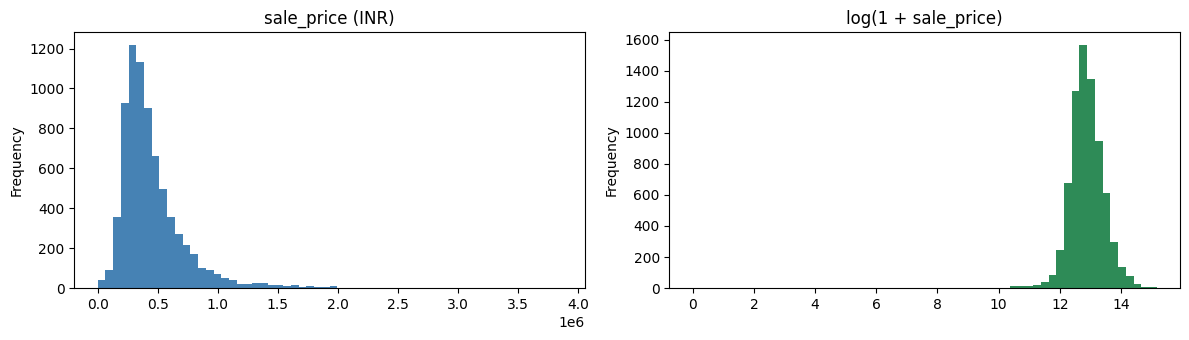

Rows with sale_price == 0: 3
Skewness of sale_price: 2.77


In [ ]:
# Look at the target. It is right-skewed (a few very expensive cars) -> this matters for MSE later.
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
df["sale_price"].plot.hist(bins=60, ax=ax[0], color="steelblue"); ax[0].set_title("sale_price (INR)")
np.log1p(df["sale_price"]).plot.hist(bins=60, ax=ax[1], color="seagreen"); ax[1].set_title("log(1 + sale_price)")
plt.tight_layout(); plt.show()
print("Rows with sale_price == 0:", int((df["sale_price"] == 0).sum()))
print("Skewness of sale_price:", round(df["sale_price"].skew(), 2))

In [ ]:
df_clean = df.drop_duplicates().copy()
df_clean = df_clean[df_clean["sale_price"].notna() & (df_clean["sale_price"] > 0)].copy()
print(f"Rows: {len(df)} -> {len(df_clean)} after dropping duplicates and price <= 0 "
      f"(allowed range: 1,000 to 200,000)")
target_col = "sale_price"

# 70 / 15 / 15 split, random, seed 42.  The TEST set is not touched again until Section 10.
train_df, temp_df = train_test_split(df_clean, test_size=0.30, random_state=42)
val_df, test_df   = train_test_split(temp_df,  test_size=0.50, random_state=42)
print("Train / Val / Test rows:", len(train_df), len(val_df), len(test_df))

Rows: 7400 -> 7396 after dropping duplicates and price <= 0 (allowed range: 1,000 to 200,000)
Train / Val / Test rows: 5177 1109 1110


In [ ]:
leak_cols  = [c for c in ["broker_quote", "emi_starts_from", "booking_down_pymnt"] if c in df_clean.columns]
print("Correlation with sale_price (train only):")
print(train_df[leak_cols + ["kms_run", "yr_mfr"]].corrwith(train_df[target_col]).round(3).to_string())

def quick_ols(cols):
    imp = SimpleImputer(strategy="median").fit(train_df[cols])
    lr = LinearRegression().fit(imp.transform(train_df[cols]), train_df[target_col])
    p = lr.predict(imp.transform(val_df[cols]))
    return r2_score(val_df[target_col], p), np.sqrt(np.mean((val_df[target_col] - p) ** 2))

honest = [c for c in ["yr_mfr", "kms_run", "total_owners", "times_viewed"] if c in df_clean.columns]
r2_a, rm_a = quick_ols(honest)
r2_b, rm_b = quick_ols(honest + leak_cols)
print(f"\nVal R^2 / RMSE without the leaky columns: {r2_a:.3f} / {rm_a:,.0f}")
print(f"Val R^2 / RMSE WITH the leaky columns   : {r2_b:.3f} / {rm_b:,.0f}   <- suspiciously good = leakage")

Correlation with sale_price (train only):
broker_quote          0.96
emi_starts_from       1.00
booking_down_pymnt    1.00
kms_run              -0.11
yr_mfr                0.52

Val R^2 / RMSE without the leaky columns: 0.281 / 257,485
Val R^2 / RMSE WITH the leaky columns   : 1.000 / 1   <- suspiciously good = leakage


In [ ]:
drop_cols = [target_col, "broker_quote", "emi_starts_from", "booking_down_pymnt",
             "car_name", "variant", "rto", "registered_city", "ad_created_on"]
drop_cols = [c for c in drop_cols if c in df_clean.columns]

def split_xy(d):
    X = d.drop(columns=drop_cols).copy()
    for c in X.select_dtypes(include=["bool"]).columns:      # bool -> 0/1 float
        X[c] = X[c].astype(np.float32)
    return X, d[target_col].to_numpy(dtype=np.float64).reshape(-1, 1)

X_train_df, y_train = split_xy(train_df)
X_val_df,   y_val   = split_xy(val_df)
X_test_df,  y_test  = split_xy(test_df)          # built now, but NOT used until Section 10

num_cols = X_train_df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = [c for c in X_train_df.columns if c not in num_cols]
print(f"{len(num_cols)} numeric columns, {len(cat_cols)} categorical columns")

num_imputer = SimpleImputer(strategy="median", add_indicator=True)   # + "was missing" flags
scaler      = StandardScaler()
cat_imputer = SimpleImputer(strategy="most_frequent")
encoder     = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

def prep(Xdf, fit=False):
    if fit:
        num = scaler.fit_transform(num_imputer.fit_transform(Xdf[num_cols]))
        cat = encoder.fit_transform(cat_imputer.fit_transform(Xdf[cat_cols]))
    else:
        num = scaler.transform(num_imputer.transform(Xdf[num_cols]))
        cat = encoder.transform(cat_imputer.transform(Xdf[cat_cols]))
    return np.hstack([num, cat]).astype(np.float32)

X_train = prep(X_train_df, fit=True)     # fit on TRAIN only
X_val   = prep(X_val_df)
X_test  = prep(X_test_df)
input_dim = X_train.shape[1]
print("Train / Val / Test shapes:", X_train.shape, X_val.shape, X_test.shape)

X_train_t = torch.tensor(X_train); X_val_t = torch.tensor(X_val)

9 numeric columns, 11 categorical columns
Train / Val / Test shapes: (5177, 265) (1109, 265) (1110, 265)


In [ ]:
BASE = dict(hidden=[64, 64, 64], opt="adam", lr=0.003, bs=64, loss="mse", epochs=30, seed=42,
            target="standard", wd=0.0, dropout=0.0, train_frac=1.0, huber_delta=1.0)

class TargetTransform:
    # kind: 'standard' (z-score, default), 'raw' (no scaling), 'log' (z-score of log price).
    # inverse() always returns predictions in INR so every MSE is on the original scale.
    def __init__(self, kind, y_ref):
        self.kind = kind
        if kind == "raw":
            self.mu, self.sd = 0.0, 1.0
        else:
            z = np.log(y_ref) if kind == "log" else y_ref
            self.mu, self.sd = float(z.mean()), float(z.std())
    def forward(self, y):
        z = np.log(y) if self.kind == "log" else y
        return ((z - self.mu) / self.sd).astype(np.float32)
    def inverse(self, z):
        v = z * self.sd + self.mu
        return np.exp(np.clip(v, -50, 30)) if self.kind == "log" else v

def make_mlp(in_dim, hidden, dropout=0.0):
    # Feed-forward net with ReLU. hidden=[] gives plain linear regression.
    layers, prev = [], in_dim
    for h in hidden:
        layers += [nn.Linear(prev, h), nn.ReLU()]
        if dropout > 0: layers.append(nn.Dropout(dropout))
        prev = h
    layers.append(nn.Linear(prev, 1))
    return nn.Sequential(*layers)

def get_optimizer(name, params, lr, wd=0.0):
    if name == "sgd":      return torch.optim.SGD(params, lr=lr, weight_decay=wd)
    if name == "momentum": return torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=wd)
    if name == "adam":     return torch.optim.Adam(params, lr=lr, weight_decay=wd)
    raise ValueError(name)

def get_loss(name, delta=1.0):
    if name == "mse":   return nn.MSELoss()
    if name == "l1":    return nn.L1Loss()
    if name == "huber": return nn.HuberLoss(delta=delta)
    raise ValueError(name)

def predict(model, X_t, tt):
    model.eval()
    with torch.no_grad():
        z = model(X_t).numpy().astype(np.float64)
    return tt.inverse(z)

def mse_np(y, p): return float(np.mean((y - p) ** 2))

def train_one(cfg, keep_model=False):
    seed = cfg["seed"]
    torch.manual_seed(seed); np.random.seed(seed)
    tt = TargetTransform(cfg["target"], y_train)

    n_all = len(X_train)
    sub = (np.random.RandomState(42).permutation(n_all)[: int(cfg["train_frac"] * n_all)]
           if cfg["train_frac"] < 1.0 else np.arange(n_all))
    Xtr_np, ytr_orig = X_train[sub], y_train[sub]
    Xtr, ytr = torch.tensor(Xtr_np), torch.tensor(tt.forward(ytr_orig))
    n = len(Xtr)

    model = make_mlp(input_dim, cfg["hidden"], cfg["dropout"])
    opt = get_optimizer(cfg["opt"], model.parameters(), cfg["lr"], cfg["wd"])
    crit = get_loss(cfg["loss"], cfg["huber_delta"])
    g = torch.Generator().manual_seed(seed)           # reproducible shuffling

    tr_hist, va_hist = [], []
    best_val, best_epoch, best_state = np.inf, -1, None
    diverged, t_train = False, 0.0
    Xtr_t = torch.tensor(Xtr_np)

    for ep in range(cfg["epochs"]):
        model.train(); t0 = time.perf_counter()
        perm = torch.randperm(n, generator=g)
        for i in range(0, n, cfg["bs"]):
            idx = perm[i:i + cfg["bs"]]
            opt.zero_grad()
            loss = crit(model(Xtr[idx]), ytr[idx])
            if not torch.isfinite(loss):
                diverged = True; break
            loss.backward(); opt.step()
        t_train += time.perf_counter() - t0
        if diverged: break

        tr = mse_np(ytr_orig, predict(model, Xtr_t, tt))
        va = mse_np(y_val,    predict(model, X_val_t, tt))
        if not (np.isfinite(tr) and np.isfinite(va)):
            diverged = True; break
        tr_hist.append(tr); va_hist.append(va)
        if va < best_val:
            best_val, best_epoch = va, ep + 1
            if keep_model: best_state = copy.deepcopy(model.state_dict())

    out = dict(diverged=diverged, tr_hist=tr_hist, va_hist=va_hist, time=t_train)
    if diverged or not va_hist:
        out.update(train_final=np.nan, val_final=np.nan, best_val=np.nan, best_epoch=np.nan, val_mae=np.nan)
    else:
        out.update(train_final=tr_hist[-1], val_final=va_hist[-1], best_val=best_val, best_epoch=best_epoch,
                   val_mae=float(mean_absolute_error(y_val, predict(model, X_val_t, tt))))
    if keep_model:
        out.update(model=model, best_state=best_state, tt=tt)
    return out

# ---------- experiment logger ----------
RESULTS, HIST, CFGS, CACHE = [], {}, {}, {}
def cfg_key(cfg): return json.dumps(cfg, sort_keys=True)

def run(topic, setting, **changes):
    cfg = {**BASE, **changes}
    k = cfg_key(cfg)
    if k not in CACHE:                       # identical config already trained -> reuse, do not retrain
        CACHE[k] = train_one(cfg)
    r = CACHE[k]
    rid = len(RESULTS) + 1
    row = {
        "Run": rid, "Topic": topic, "Setting": setting,
        "Changed": ", ".join(f"{c}={cfg[c]}" for c in BASE if cfg[c] != BASE[c]) or "-",
        "Train MSE": r["train_final"], "Val MSE": r["val_final"], "Best Val MSE": r["best_val"],
        "Best epoch": r["best_epoch"], "Val RMSE": np.sqrt(r["best_val"]) if r["best_val"] == r["best_val"] else np.nan,
        "Val MAE": r["val_mae"], "Time (s)": round(r["time"], 1),
        "Status": "DIVERGED (NaN)" if r["diverged"] else "ok",
        "Final/Best": (r["val_final"] / r["best_val"]) if r["best_val"] == r["best_val"] else np.nan,
    }
    RESULTS.append(row); HIST[rid] = (r["tr_hist"], r["va_hist"]); CFGS[rid] = cfg
    bv = row["Best Val MSE"]
    print(f"Run {rid:>2} | {topic:<16} | {setting:<48} | best val MSE = {bv:>18,.0f} | {row['Time (s)']:>5.1f}s | {row['Status']}")
    return row

def table(topics=None, cols=None):
    d = pd.DataFrame(RESULTS)
    if topics is not None: d = d[d["Topic"].isin(topics)]
    cols = cols or ["Run", "Topic", "Setting", "Train MSE", "Val MSE", "Best Val MSE", "Best epoch",
                    "Val RMSE", "Val MAE", "Time (s)", "Status", "Final/Best"]
    return d[cols].to_string(index=False)

def plot_topic(topics, title=None, ref=True):
    # Training (left) and validation (right) loss per epoch for every run in the topic; log y-axis.
    ids = [r["Run"] for r in RESULTS if r["Topic"] in topics]
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
    for rid in ids:
        tr, va = HIST[rid]
        lab = f"#{rid} " + next(r["Setting"] for r in RESULTS if r["Run"] == rid)
        if len(va): ax[0].plot(range(1, len(tr) + 1), tr, label=lab, lw=1.3); ax[1].plot(range(1, len(va) + 1), va, label=lab, lw=1.3)
    if ref and "LIN_REF_VAL" in globals():
        ax[1].axhline(LIN_REF_VAL, color="k", ls="--", lw=1, label=f"Linear regression (val): {LIN_REF_VAL:,.0f}")
    for a, t in zip(ax, ["Training MSE per epoch", "Validation MSE per epoch"]):
        a.set_yscale("log"); a.set_xlabel("Epoch"); a.set_title(t); a.grid(alpha=0.3)
    ax[0].set_ylabel("MSE (INR², log scale)")
    ax[1].legend(fontsize=7, loc="upper right", ncol=1)
    fig.suptitle(title or ", ".join(topics)); plt.tight_layout()
    fname = "fig_" + "".join(c if c.isalnum() else "_" for c in (title or topics[0])) + ".png"
    fig.savefig(fname, dpi=150); plt.show()

=== Baselines ===
Run  1 | Baseline         | Linear regression (no hidden layers)             | best val MSE =     11,421,528,325 |   2.7s | ok
Run  2 | Baseline         | Reference NN [64,64,64], Adam, lr 0.003, bs 64, MSE | best val MSE =      3,859,227,083 |   5.2s | ok

Closed-form OLS     -> Train MSE: 6,954,798,869 | Val MSE: 14,152,976,839
Strictest linear reference on validation: Adam-trained linear model, MSE = 11,421,528,325
Reference NN best val MSE = 3,859,227,083  ->  66.2% lower than linear

 Run    Topic                                             Setting        Train MSE           Val MSE      Best Val MSE  Best epoch   Val RMSE   Val MAE  Time (s) Status  Final/Best
   1 Baseline                Linear regression (no hidden layers) 8,755,367,972.57 12,093,072,224.51 11,421,528,325.25          15 106,871.55 57,462.36      2.70     ok        1.06
   2 Baseline Reference NN [64,64,64], Adam, lr 0.003, bs 64, MSE   792,709,908.83  4,006,312,706.99  3,859,227,083.17        

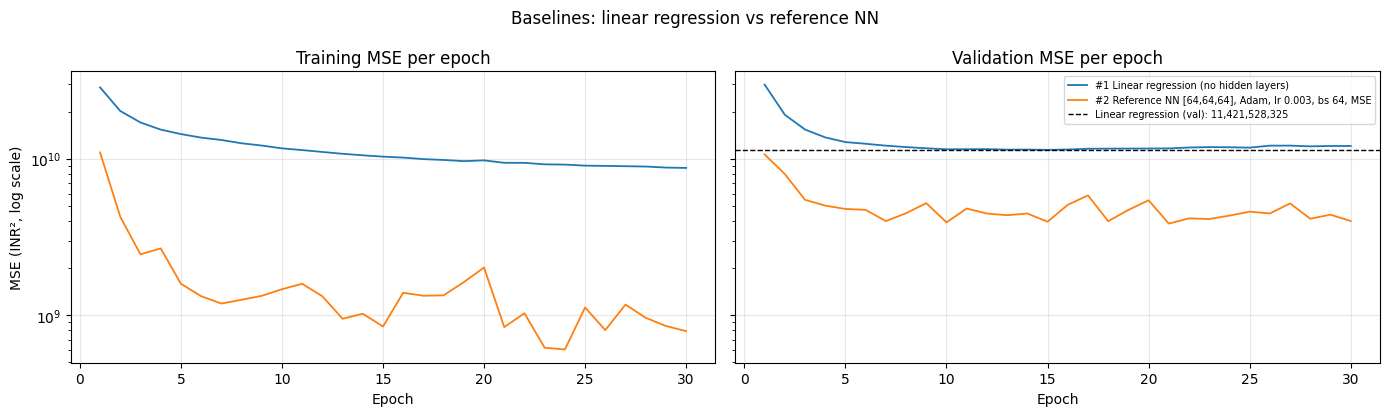

In [ ]:
print("=== Baselines ===")
run("Baseline", "Linear regression (no hidden layers)", hidden=[])
run("Baseline", "Reference NN [64,64,64], Adam, lr 0.003, bs 64, MSE")

ols = LinearRegression().fit(X_train, y_train)                    # closed-form OLS reference
ols_train, ols_val = mse_np(y_train, ols.predict(X_train)), mse_np(y_val, ols.predict(X_val))
print(f"\nClosed-form OLS     -> Train MSE: {ols_train:,.0f} | Val MSE: {ols_val:,.0f}")

lin_best = RESULTS[0]["Best Val MSE"]; nn_best = RESULTS[1]["Best Val MSE"]
LIN_REF_VAL = min(lin_best, ols_val)                               # strictest linear reference
LIN_REF_NAME = "closed-form OLS" if ols_val <= lin_best else "Adam-trained linear model"
print(f"Strictest linear reference on validation: {LIN_REF_NAME}, MSE = {LIN_REF_VAL:,.0f}")
print(f"Reference NN best val MSE = {nn_best:,.0f}  ->  {100*(LIN_REF_VAL-nn_best)/LIN_REF_VAL:.1f}% lower than linear\n")
print(table(["Baseline"]))
plot_topic(["Baseline"], title="Baselines: linear regression vs reference NN")

In [ ]:
for s in [1, 2, 3, 4, 5]:
    run("Noise floor", f"Reference NN, seed = {s}", seed=s)

noise_vals = np.array([RESULTS[1]["Best Val MSE"]] + [r["Best Val MSE"] for r in RESULTS if r["Topic"] == "Noise floor"])
NOISE_MEAN, NOISE_SD = noise_vals.mean(), noise_vals.std(ddof=1)
print(f"\nReference NN over 6 seeds: mean best-val MSE = {NOISE_MEAN:,.0f}, std = {NOISE_SD:,.0f} "
      f"({100*NOISE_SD/NOISE_MEAN:.1f}% of the mean)")
print(f"Rule used below: a change counts as a *real* improvement only if it beats the reference by more than 2 x std "
      f"= {2*NOISE_SD:,.0f}")

# Bootstrap the validation set (same model, resampled validation rows)
rb = train_one(BASE, keep_model=True)
rb["model"].load_state_dict(rb["best_state"])
sq_err = (y_val - predict(rb["model"], X_val_t, rb["tt"])) ** 2
rng = np.random.RandomState(0)
boot = np.array([sq_err[rng.randint(0, len(sq_err), len(sq_err))].mean() for _ in range(2000)])
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Bootstrap 95% interval for the reference NN's validation MSE: [{lo:,.0f}, {hi:,.0f}]  "
      f"(+/- {100*(hi-lo)/2/boot.mean():.0f}% )")

Run  3 | Noise floor      | Reference NN, seed = 1                           | best val MSE =      3,626,944,055 |   5.8s | ok
Run  4 | Noise floor      | Reference NN, seed = 2                           | best val MSE =      3,839,092,674 |   6.5s | ok
Run  5 | Noise floor      | Reference NN, seed = 3                           | best val MSE =      4,061,553,201 |   8.2s | ok
Run  6 | Noise floor      | Reference NN, seed = 4                           | best val MSE =      4,651,588,464 |  13.1s | ok
Run  7 | Noise floor      | Reference NN, seed = 5                           | best val MSE =      4,071,533,447 |   7.7s | ok

Reference NN over 6 seeds: mean best-val MSE = 4,018,323,154, std = 351,094,816 (8.7% of the mean)
Rule used below: a change counts as a *real* improvement only if it beats the reference by more than 2 x std = 702,189,632
Bootstrap 95% interval for the reference NN's validation MSE: [2,028,181,399, 6,936,499,564]  (+/- 64% )


Run  8 | Learning rate    | Adam lr = 0.0001                                 | best val MSE =      4,149,115,689 |   6.2s | ok
Run  9 | Learning rate    | Adam lr = 0.0005                                 | best val MSE =      3,716,654,027 |   4.4s | ok
Run 10 | Learning rate    | Adam lr = 0.001                                  | best val MSE =      3,748,075,791 |   4.9s | ok
Run 11 | Learning rate    | Adam lr = 0.01                                   | best val MSE =      4,472,937,705 |   5.6s | ok
Run 12 | Learning rate    | Adam lr = 0.05                                   | best val MSE =      5,078,823,556 |   6.0s | ok
Run 13 | Learning rate    | Adam lr = 0.5                                    | best val MSE =    103,262,914,322 |   6.0s | ok

 Run         Topic          Setting         Train MSE            Val MSE       Best Val MSE  Best epoch   Val RMSE    Val MAE  Time (s) Status  Final/Best
   8 Learning rate Adam lr = 0.0001  2,355,954,971.97   4,149,115,688.71   4,149,1

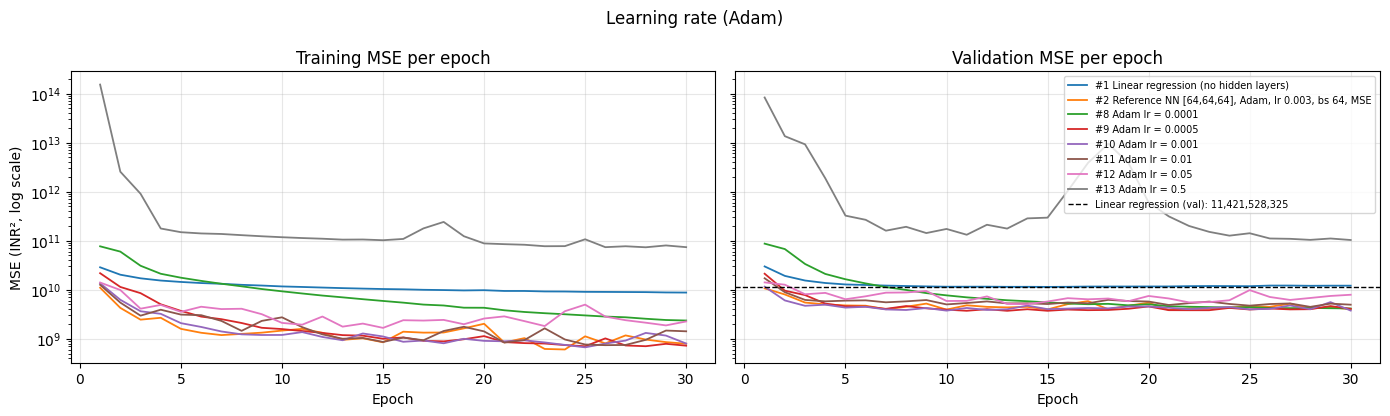

In [ ]:
for lr in [0.0001, 0.0005, 0.001, 0.01, 0.05, 0.5]:
    run("Learning rate", f"Adam lr = {lr}", lr=lr)
print(); print(table(["Learning rate"])); plot_topic(["Learning rate", "Baseline"], title="Learning rate (Adam)", ref=True)

Run 14 | Optimizer        | SGD (lr 0.003)                                   | best val MSE =     16,115,733,674 |   3.0s | ok
Run 15 | Optimizer        | SGD + momentum 0.9 (lr 0.003)                    | best val MSE =      3,999,689,846 |   3.2s | ok
Run 16 | Optimizer        | [fairness] SGD lr 0.03                           | best val MSE =      4,107,100,501 |   2.3s | ok
Run 17 | Optimizer        | [fairness] SGD lr 0.1                            | best val MSE =      4,598,867,496 |   2.4s | ok
Run 18 | Optimizer        | [fairness] SGD + momentum lr 0.03                | best val MSE =      4,410,959,571 |   3.2s | ok

 Run     Topic                           Setting         Train MSE           Val MSE      Best Val MSE  Best epoch   Val RMSE   Val MAE  Time (s) Status  Final/Best
  14 Optimizer                    SGD (lr 0.003) 18,916,373,379.92 16,115,733,673.79 16,115,733,673.79          30 126,947.76 73,333.16      3.00     ok        1.00
  15 Optimizer     SGD + momentum 

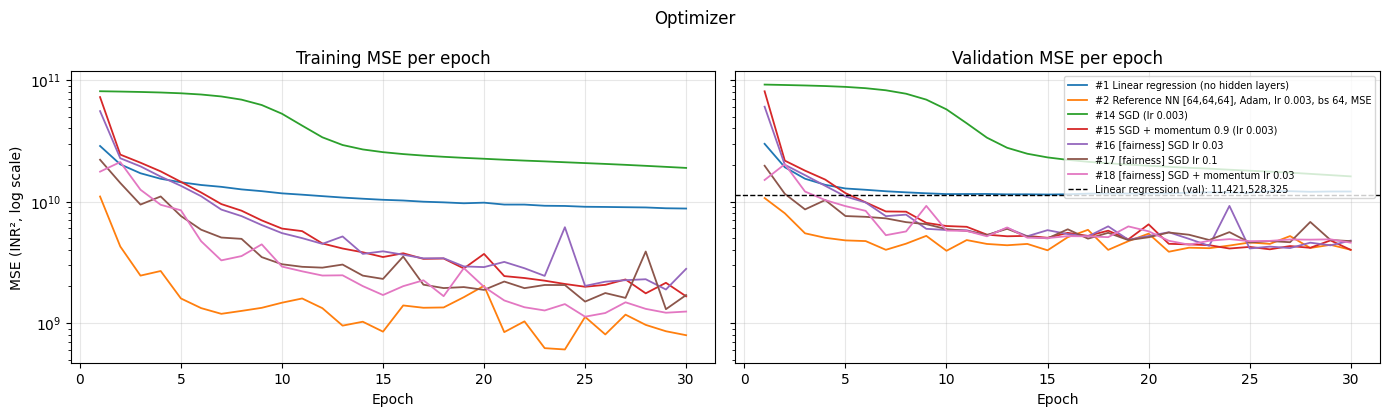

In [ ]:
run("Optimizer", "SGD (lr 0.003)", opt="sgd")
run("Optimizer", "SGD + momentum 0.9 (lr 0.003)", opt="momentum")
run("Optimizer", "[fairness] SGD lr 0.03", opt="sgd", lr=0.03)
run("Optimizer", "[fairness] SGD lr 0.1", opt="sgd", lr=0.1)
run("Optimizer", "[fairness] SGD + momentum lr 0.03", opt="momentum", lr=0.03)
print(); print(table(["Optimizer"])); plot_topic(["Optimizer", "Baseline"], title="Optimizer", ref=True)

Run 19 | Batch size       | batch size = 8                                   | best val MSE =      4,266,401,778 |  36.8s | ok
Run 20 | Batch size       | batch size = 16                                  | best val MSE =      4,059,557,468 |  17.1s | ok
Run 21 | Batch size       | batch size = 32                                  | best val MSE =      4,022,005,387 |   8.9s | ok
Run 22 | Batch size       | batch size = 128                                 | best val MSE =      4,322,102,609 |   2.1s | ok
Run 23 | Batch size       | batch size = 256                                 | best val MSE =      3,500,402,740 |   1.3s | ok
Run 24 | Batch size       | batch size = 512                                 | best val MSE =      3,517,899,598 |   1.0s | ok

 Run      Topic          Setting        Train MSE          Val MSE     Best Val MSE  Best epoch  Val RMSE   Val MAE  Time (s) Status  Final/Best
  19 Batch size   batch size = 8 1,155,526,729.75 4,266,401,777.85 4,266,401,777.85         

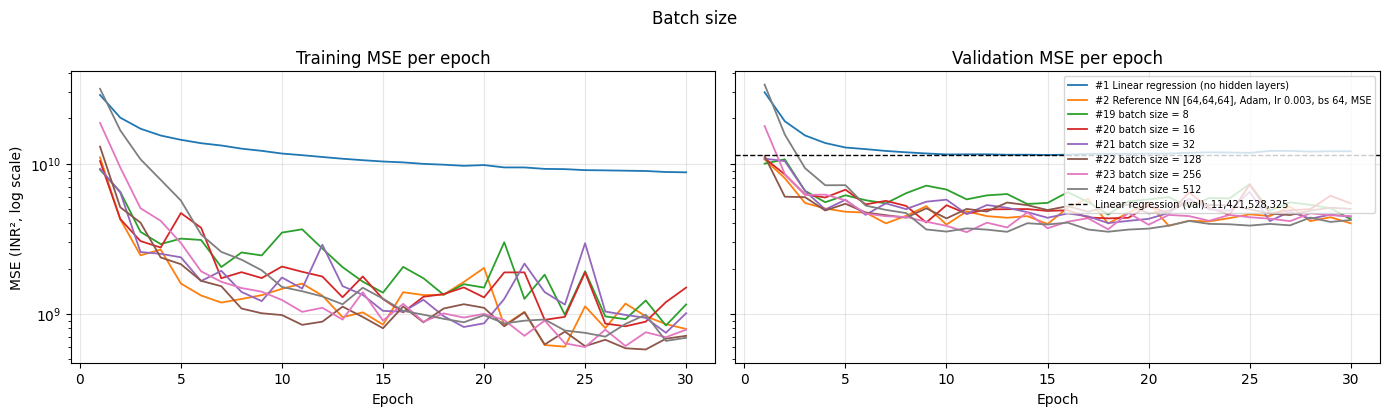

In [ ]:
for bs in [8, 16, 32, 128, 256, 512]:
    run("Batch size", f"batch size = {bs}", bs=bs)
print(); print(table(["Batch size"])); plot_topic(["Batch size", "Baseline"], title="Batch size", ref=True)

Run 25 | Depth and width  | hidden = [32]                                    | best val MSE =      4,444,650,034 |   2.3s | ok
Run 26 | Depth and width  | hidden = [64]                                    | best val MSE =      4,342,987,422 |   2.6s | ok
Run 27 | Depth and width  | hidden = [128]                                   | best val MSE =      4,098,366,881 |   3.4s | ok
Run 28 | Depth and width  | hidden = [256]                                   | best val MSE =      3,437,042,941 |   5.9s | ok
Run 29 | Depth and width  | hidden = [32, 32]                                | best val MSE =      4,248,586,168 |   2.7s | ok
Run 30 | Depth and width  | hidden = [128, 128]                              | best val MSE =      3,914,817,120 |   4.6s | ok
Run 31 | Depth and width  | hidden = [256, 256]                              | best val MSE =      4,140,716,297 |   9.4s | ok
Run 32 | Depth and width  | hidden = [128, 128, 128]                         | best val MSE =      4,366,328,89

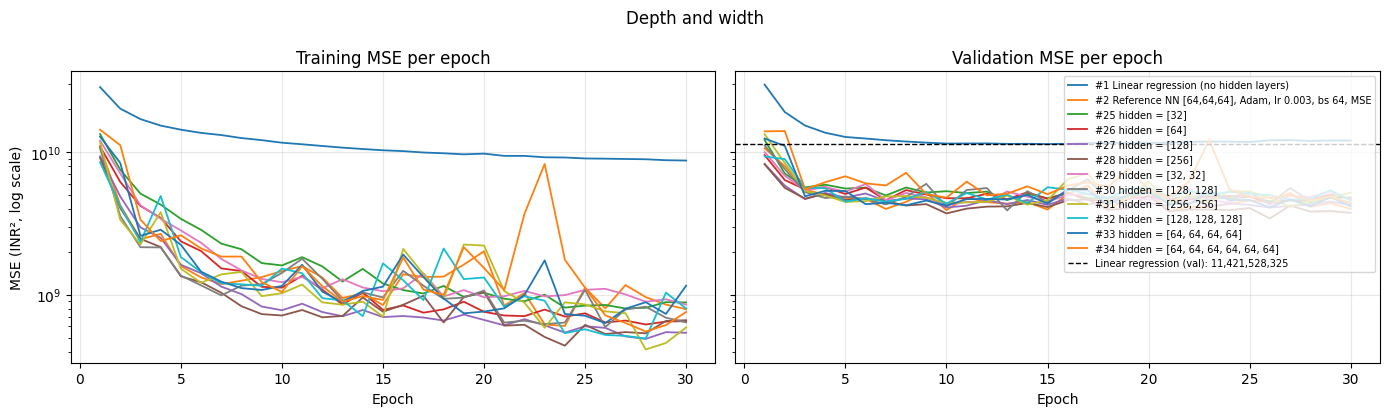

In [ ]:
for hd in [[32], [64], [128], [256], [32, 32], [128, 128], [256, 256], [128, 128, 128], [64, 64, 64, 64], [64] * 6]:
    run("Depth and width", f"hidden = {hd}", hidden=hd)
print(); print(table(["Depth and width"])); plot_topic(["Depth and width", "Baseline"], title="Depth and width", ref=True)

Run 35 | Loss function    | L1 loss                                          | best val MSE =      3,991,786,227 |   4.8s | ok
Run 36 | Loss function    | Huber loss (delta = 1.0)                         | best val MSE =      3,403,607,857 |   4.1s | ok
Run 37 | Loss function    | Huber loss (delta = 0.1)                         | best val MSE =      4,284,955,459 |   4.7s | ok

 Run         Topic                  Setting      Train MSE          Val MSE     Best Val MSE  Val RMSE   Val MAE  Time (s) Status
  35 Loss function                  L1 loss 869,632,130.11 5,459,465,625.99 3,991,786,227.20 63,180.58 32,578.23      4.80     ok
  36 Loss function Huber loss (delta = 1.0) 892,524,161.23 4,016,262,824.28 3,403,607,857.25 58,340.45 32,016.25      4.10     ok
  37 Loss function Huber loss (delta = 0.1) 638,014,418.71 5,132,835,647.33 4,284,955,458.97 65,459.57 32,209.83      4.70     ok

Reference NN (MSE loss) Val MAE: 31,196


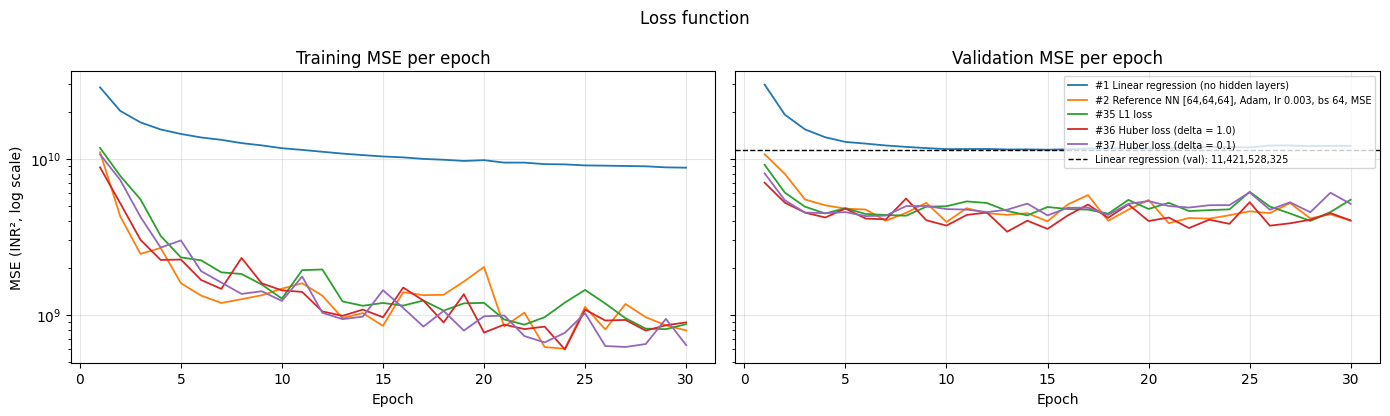

In [ ]:
run("Loss function", "L1 loss", loss="l1")
run("Loss function", "Huber loss (delta = 1.0)", loss="huber", huber_delta=1.0)
run("Loss function", "Huber loss (delta = 0.1)", loss="huber", huber_delta=0.1)
print(); print(table(["Loss function"], cols=["Run","Topic","Setting","Train MSE","Val MSE","Best Val MSE","Val RMSE","Val MAE","Time (s)","Status"]))
print("\nReference NN (MSE loss) Val MAE:", f"{[r for r in RESULTS if r['Run']==2][0]['Val MAE']:,.0f}")
plot_topic(["Loss function", "Baseline"], title="Loss function", ref=True)

Run 38 | Extra: target    | raw target (no scaling)                          | best val MSE =      6,008,367,835 |   3.8s | ok
Run 39 | Extra: target    | log-price target                                 | best val MSE =      3,704,245,832 |   4.2s | ok
Run 40 | Extra: regularization | weight decay = 1e-05                             | best val MSE =      3,772,942,904 |   5.2s | ok
Run 41 | Extra: regularization | weight decay = 0.0001                            | best val MSE =      4,034,789,801 |   4.7s | ok
Run 42 | Extra: regularization | weight decay = 0.001                             | best val MSE =      3,815,924,157 |   5.6s | ok
Run 43 | Extra: regularization | dropout = 0.1                                    | best val MSE =      4,235,706,818 |   5.0s | ok
Run 44 | Extra: regularization | dropout = 0.3                                    | best val MSE =      5,648,099,181 |   5.4s | ok
Run 45 | Extra: train size | 10% of training rows (517 rows)                  | best v

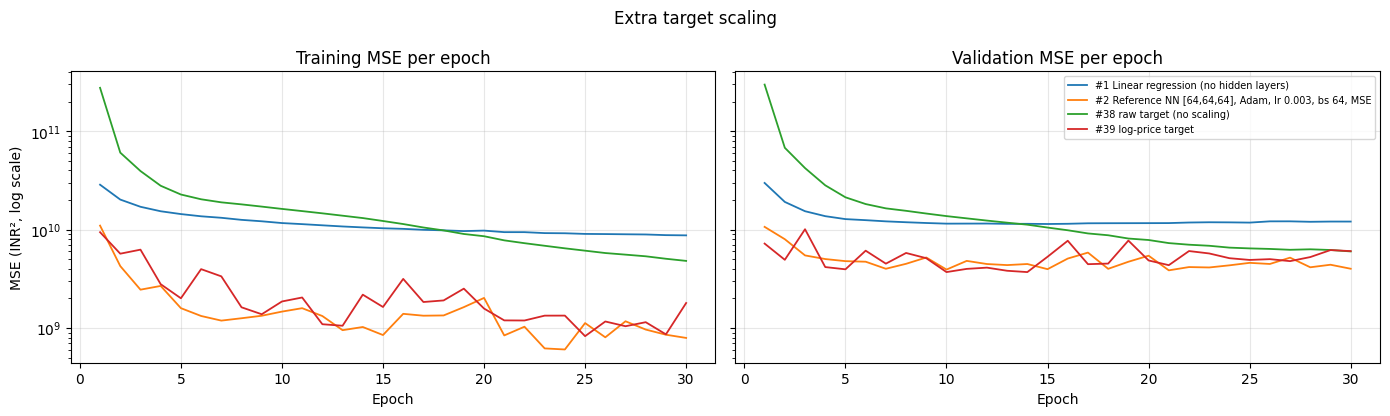

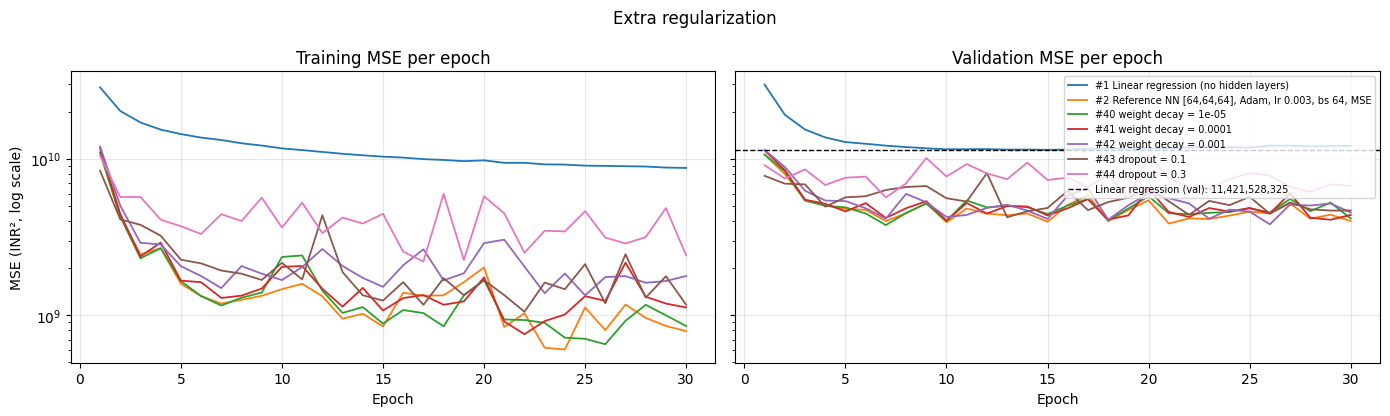

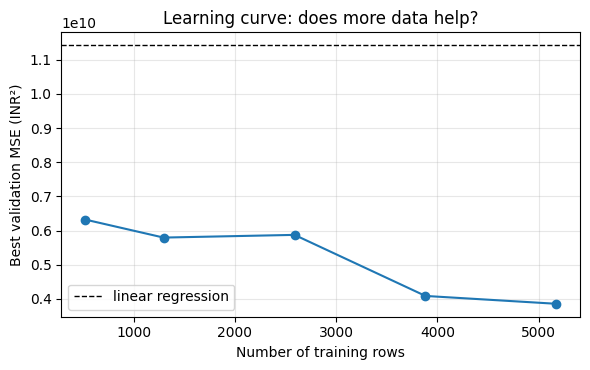

In [ ]:
# --- target preprocessing ---
run("Extra: target", "raw target (no scaling)", target="raw")
run("Extra: target", "log-price target", target="log")
# --- regularization ---
for wd in [1e-5, 1e-4, 1e-3]:
    run("Extra: regularization", f"weight decay = {wd}", wd=wd)
for p in [0.1, 0.3]:
    run("Extra: regularization", f"dropout = {p}", dropout=p)
# --- training-set size (validation set is unchanged, so the numbers are comparable) ---
for fr in [0.1, 0.25, 0.5, 0.75]:
    run("Extra: train size", f"{int(fr*100)}% of training rows ({int(fr*len(X_train))} rows)", train_frac=fr)

print(); print(table(["Extra: target", "Extra: regularization", "Extra: train size"]))
plot_topic(["Extra: target", "Baseline"], title="Extra target scaling", ref=False)
plot_topic(["Extra: regularization", "Baseline"], title="Extra regularization", ref=True)

# learning curve
fr_rows = [(CFGS[r["Run"]]["train_frac"], r["Best Val MSE"]) for r in RESULTS if r["Topic"] == "Extra: train size"] + [(1.0, RESULTS[1]["Best Val MSE"])]
fr_rows.sort()
plt.figure(figsize=(6, 3.8))
plt.plot([f * len(X_train) for f, _ in fr_rows], [v for _, v in fr_rows], "o-")
plt.axhline(LIN_REF_VAL, color="k", ls="--", lw=1, label="linear regression")
plt.xlabel("Number of training rows"); plt.ylabel("Best validation MSE (INR²)"); plt.title("Learning curve: does more data help?")
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.savefig("fig_learning_curve.png", dpi=150); plt.show()

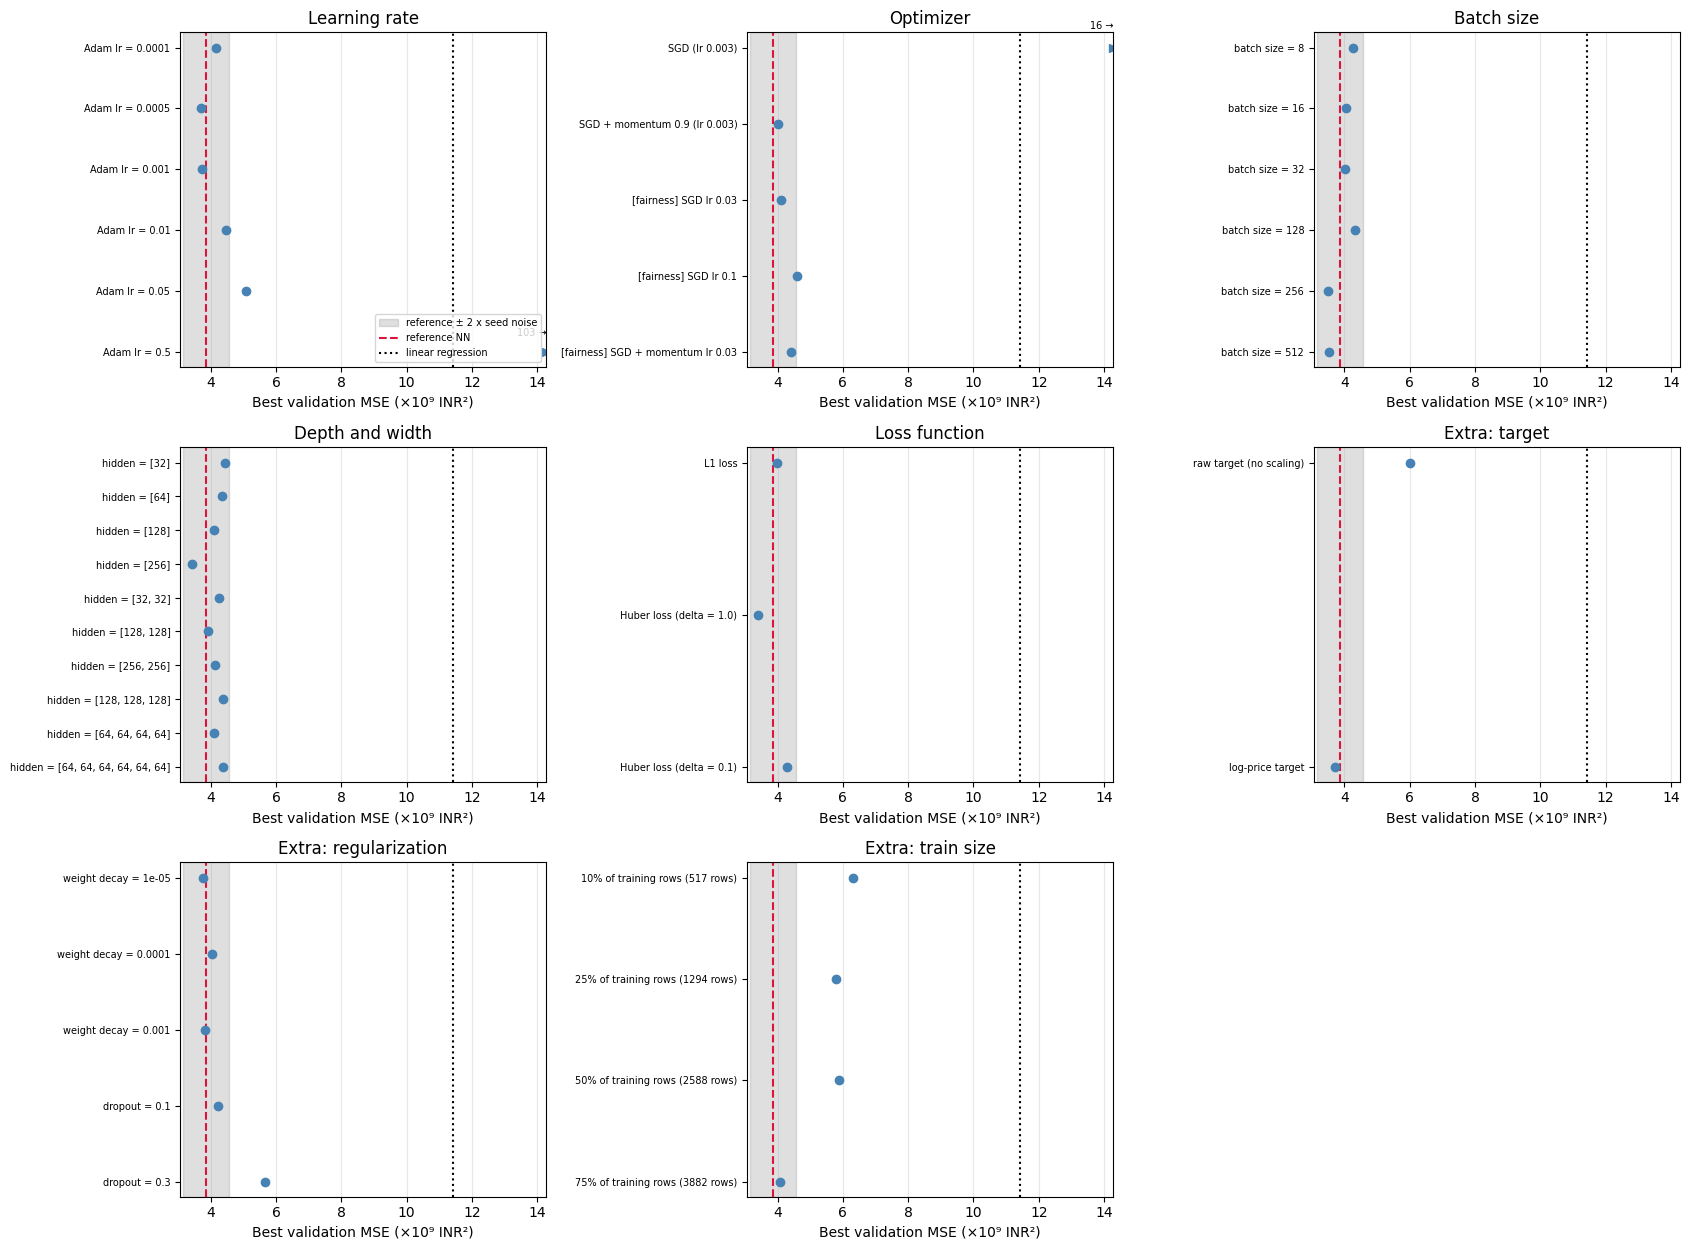

Experiments in the 5 required topics: 30   |   total runs logged (incl. baselines, noise, extras): 48
Diverged runs: 0   ->  []


In [ ]:
# Overview: best validation MSE of every run, grouped by topic. Grey band = reference +/- 2 x seed noise.
results_df = pd.DataFrame(RESULTS)
results_df.to_csv("experiment_results.csv", index=False)
ref_val = RESULTS[1]["Best Val MSE"]
topics_all = [t for t in results_df["Topic"].unique() if t not in ("Baseline", "Noise floor")]
ncols = 3; nrows = int(np.ceil(len(topics_all) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(17, 4.2 * nrows)); axes = np.array(axes).flatten()
B = 1e9                                                     # show values in billions of INR² (easier to read)
x_hi = 1.25 * LIN_REF_VAL / B                               # runs far worse than linear are clipped and labelled
for ax, t in zip(axes, topics_all):
    sub = results_df[results_df["Topic"] == t].dropna(subset=["Best Val MSE"])
    ys = np.arange(len(sub)); xs = sub["Best Val MSE"].to_numpy() / B
    ax.axvspan((ref_val - 2 * NOISE_SD) / B, (ref_val + 2 * NOISE_SD) / B, color="grey", alpha=0.25, label="reference ± 2 x seed noise")
    ax.axvline(ref_val / B, color="crimson", ls="--", label="reference NN")
    ax.axvline(LIN_REF_VAL / B, color="k", ls=":", label="linear regression")
    for y, x, name in zip(ys, xs, sub["Setting"]):
        if x > x_hi: ax.plot([x_hi], [y], ">", color="steelblue"); ax.text(x_hi, y - 0.25, f"{x:,.0f} →", ha="right", fontsize=7)
        else:        ax.plot([x], [y], "o", color="steelblue")
    ax.set_yticks(ys); ax.set_yticklabels(sub["Setting"], fontsize=7); ax.invert_yaxis(); ax.grid(axis="x", alpha=0.3)
    ax.set_xlim(min(xs.min(), (ref_val - 2 * NOISE_SD) / B) * 0.97, x_hi)
    ax.set_title(t); ax.set_xlabel("Best validation MSE (×10⁹ INR²)")
axes[0].legend(fontsize=7, loc="lower right")
for ax in axes[len(topics_all):]: ax.axis("off")
plt.tight_layout(); plt.savefig("fig_overview.png", dpi=150); plt.show()

n_req = int(results_df["Topic"].isin(["Learning rate","Optimizer","Batch size","Depth and width","Loss function"]).sum())
print(f"Experiments in the 5 required topics: {n_req}   |   total runs logged (incl. baselines, noise, extras): {len(results_df)}")
print(f"Diverged runs: {int((results_df['Status'] != 'ok').sum())}   -> ", results_df.loc[results_df['Status'] != 'ok', 'Setting'].tolist())

In [ ]:
REQUIRED = ["Learning rate", "Optimizer", "Batch size", "Depth and width", "Loss function"]
ref_row = RESULTS[1]
summary = []
for t in REQUIRED:
    sub = results_df[(results_df["Topic"] == t)].dropna(subset=["Best Val MSE"]).sort_values("Best Val MSE")
    best = sub.iloc[0]
    gain = ref_val - best["Best Val MSE"]
    summary.append({"Topic": t, "Best setting": best["Setting"], "Best Val MSE": best["Best Val MSE"],
                    "% vs reference": 100 * (best["Best Val MSE"] - ref_val) / ref_val,
                    "Beats noise (>2 SD)?": bool(gain > 2 * NOISE_SD), "run": int(best["Run"])})
summary_df = pd.DataFrame(summary)
print(summary_df.drop(columns="run").to_string(index=False))

# 2. combined configuration from the winners that beat noise
combined = dict(BASE)
for s in summary:
    if s["Beats noise (>2 SD)?"]:
        for k in BASE:
            if CFGS[s["run"]][k] != BASE[k]:
                combined[k] = CFGS[s["run"]][k]
print("\nCombined configuration (changes vs BASE):", {k: v for k, v in combined.items() if v != BASE[k]} or "none, the reference already stands")

# 3. candidates = top-3 single runs (eligible) + combined + reference; evaluate each over 4 seeds
eligible = results_df[results_df["Status"].eq("ok") & results_df["Topic"].isin(REQUIRED + ["Extra: regularization", "Extra: target"])]
eligible = eligible[[CFGS[r]["train_frac"] == 1.0 and CFGS[r]["target"] != "raw" for r in eligible["Run"]]]
cands, seen = {}, set()
def add_cand(name, cfg):
    k = cfg_key({**cfg, "seed": 42})
    if k not in seen:                                   # skip duplicates (e.g. combined == a single winner)
        seen.add(k); cands[name] = cfg
add_cand("reference NN", dict(BASE))
add_cand("combined winners", combined)
for _, r in eligible.sort_values("Best Val MSE").head(3).iterrows():
    add_cand(f"run {int(r['Run'])}: {r['Setting']}", dict(CFGS[int(r["Run"])]))

SEEDS = [42, 1, 2, 3]
rows = []
for name, cfg in cands.items():
    vals = [train_one({**cfg, "seed": s})["best_val"] for s in SEEDS]
    rows.append({"Candidate": name, "mean best Val MSE": np.mean(vals), "std": np.std(vals, ddof=1), "min": np.min(vals), "max": np.max(vals), "cfg": cfg})
sel_df = pd.DataFrame(rows).sort_values("mean best Val MSE")
print("\nCandidates, 4 seeds each (validation only):")
print(sel_df.drop(columns="cfg").to_string(index=False))

BEST_NAME = sel_df.iloc[0]["Candidate"]; BEST_CFG = {**sel_df.iloc[0]["cfg"], "seed": 42}
print("\nSELECTED (by mean validation MSE):", BEST_NAME)
print("Configuration:", {k: BEST_CFG[k] for k in ["hidden", "opt", "lr", "bs", "loss", "epochs", "target", "wd", "dropout", "huber_delta"]})

          Topic                  Best setting     Best Val MSE  % vs reference  Beats noise (>2 SD)?
  Learning rate              Adam lr = 0.0005 3,716,654,027.36           -3.69                 False
      Optimizer SGD + momentum 0.9 (lr 0.003) 3,999,689,845.68            3.64                 False
     Batch size              batch size = 256 3,500,402,739.92           -9.30                 False
Depth and width                hidden = [256] 3,437,042,941.06          -10.94                 False
  Loss function      Huber loss (delta = 1.0) 3,403,607,857.25          -11.81                 False

Combined configuration (changes vs BASE): none, the reference already stands

Candidates, 4 seeds each (validation only):
                       Candidate  mean best Val MSE            std              min              max
          run 28: hidden = [256]   3,610,624,610.27 117,736,449.38 3,437,042,941.06 3,695,438,844.84
run 36: Huber loss (delta = 1.0)   3,637,186,829.98 206,659,254.27 3,

In [ ]:
final = train_one(BEST_CFG, keep_model=True)
final["model"].load_state_dict(final["best_state"])
final_model, final_tt = final["model"], final["tt"]

lin = train_one({**BASE, "hidden": []}, keep_model=True)          # linear reference (same recipe as baseline)
lin["model"].load_state_dict(lin["best_state"])

print(f"Selected config: {BEST_NAME}")
print(f"Best epoch (chosen on validation): {final['best_epoch']}")
TRAIN_AT_BEST = final["tr_hist"][final["best_epoch"] - 1]
print(f"Final model  -> Train MSE (at chosen epoch): {TRAIN_AT_BEST:,.0f} | best Val MSE: {final['best_val']:,.0f} "
      f"(RMSE {np.sqrt(final['best_val']):,.0f} INR)")
print(f"Linear regression reference ({LIN_REF_NAME}) Val MSE: {LIN_REF_VAL:,.0f} (RMSE {np.sqrt(LIN_REF_VAL):,.0f} INR)")
VAL_IMPROVEMENT = 100 * (LIN_REF_VAL - final["best_val"]) / LIN_REF_VAL
print(f"==> Validation MSE improvement over linear regression: {VAL_IMPROVEMENT:.1f}%")
print(f"==> Improvement over the un-tuned reference NN       : {100*(ref_val-final['best_val'])/ref_val:.1f}%  "
      f"(seed noise is about {100*NOISE_SD/NOISE_MEAN:.1f}%)")

Selected config: run 28: hidden = [256]
Best epoch (chosen on validation): 26
Final model  -> Train MSE (at chosen epoch): 531,112,437 | best Val MSE: 3,437,042,941 (RMSE 58,626 INR)
Linear regression reference (Adam-trained linear model) Val MSE: 11,421,528,325 (RMSE 106,872 INR)
==> Validation MSE improvement over linear regression: 69.9%
==> Improvement over the un-tuned reference NN       : 10.9%  (seed noise is about 8.7%)


=== TEST SET (evaluated once) ===
                                   MSE   RMSE    MAE     R2
Linear (Adam-trained)    6,635,952,407 81,461 54,126 0.8869
Linear (closed-form OLS) 8,100,621,098 90,003 53,733 0.8619
FINAL MODEL              2,007,254,110 44,802 27,733 0.9658

Final model test MSE = 2,007,254,110 INR²  (RMSE ≈ 44,802 INR, MAE ≈ 27,733 INR, R² = 0.966)
Test MSE is 69.8% lower than the better linear model; validation said 69.9% -> the two should be similar if validation was a fair guide.


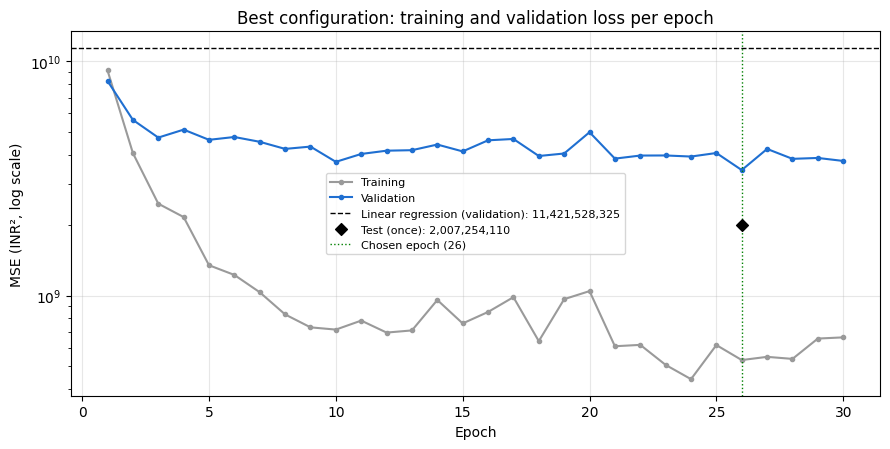

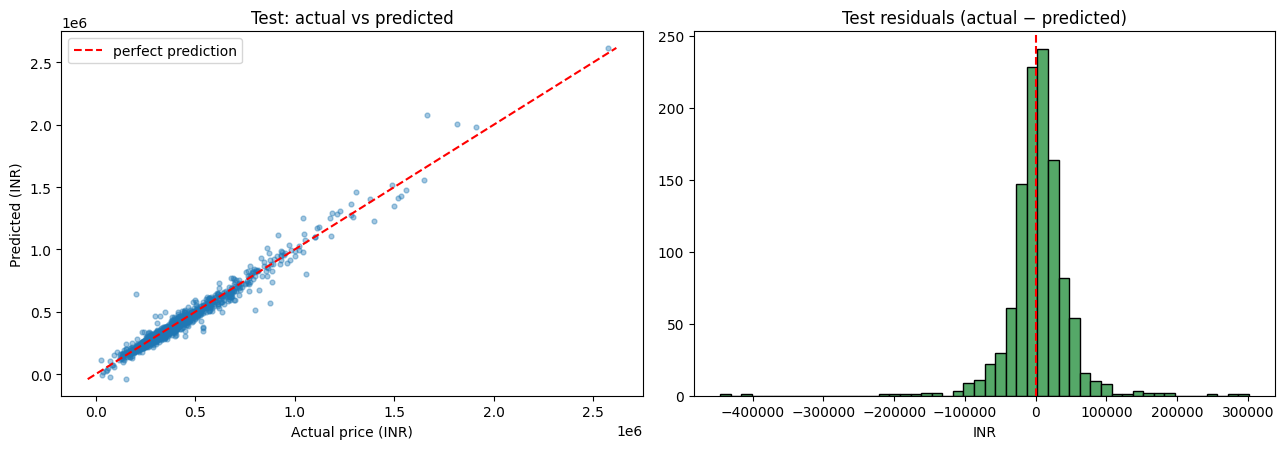

Absolute error percentiles (INR): {50: 18458, 75: 34983, 90: 58649, 95: 79501, 99: 167900}
Share of total squared error caused by the worst 5% of cars: 62%


In [ ]:
# ===================== THE ONE AND ONLY TEST-SET EVALUATION =====================
# All choices (features, architecture, optimizer, lr, batch size, loss, epoch) are frozen above and were made on
# VALIDATION data. This cell may be run once; restart the runtime to re-run it (that is deliberate).
assert "TEST_USED" not in globals(), "Test set already used once. Restart the runtime to repeat; do not re-tune on test."
TEST_USED = True

X_test_t = torch.tensor(X_test)
p_test = predict(final_model, X_test_t, final_tt).reshape(-1)
y_t = y_test.reshape(-1)
test_mse  = float(np.mean((y_t - p_test) ** 2)); test_rmse = float(np.sqrt(test_mse))
test_mae  = float(mean_absolute_error(y_t, p_test)); test_r2 = float(r2_score(y_t, p_test))

# reference models, reported only for context (they were NOT used to make any decision)
p_lin_nn  = predict(lin["model"], X_test_t, lin["tt"]).reshape(-1)
p_lin_ols = ols.predict(X_test).reshape(-1)
def metrics(p): return dict(MSE=float(np.mean((y_t-p)**2)), RMSE=float(np.sqrt(np.mean((y_t-p)**2))),
                            MAE=float(mean_absolute_error(y_t, p)), R2=float(r2_score(y_t, p)))
comp = pd.DataFrame({"Linear (Adam-trained)": metrics(p_lin_nn), "Linear (closed-form OLS)": metrics(p_lin_ols),
                     f"FINAL MODEL": metrics(p_test)}).T
print("=== TEST SET (evaluated once) ===")
print(comp.to_string(float_format=lambda x: f"{x:,.4f}" if abs(x) < 10 else f"{x:,.0f}"))
lin_test_ref = min(metrics(p_lin_nn)["MSE"], metrics(p_lin_ols)["MSE"])
print(f"\nFinal model test MSE = {test_mse:,.0f} INR²  (RMSE ≈ {test_rmse:,.0f} INR, MAE ≈ {test_mae:,.0f} INR, R² = {test_r2:.3f})")
print(f"Test MSE is {100*(lin_test_ref-test_mse)/lin_test_ref:.1f}% lower than the better linear model; "
      f"validation said {VAL_IMPROVEMENT:.1f}% -> the two should be similar if validation was a fair guide.")

# ---- the loss figure required by the assignment: train & val per epoch, linear reference, test point ----
fig, ax = plt.subplots(figsize=(9, 4.6))
ep = range(1, len(final["tr_hist"]) + 1)
ax.plot(ep, final["tr_hist"], color="#9a9a9a", marker="o", ms=3, label="Training")
ax.plot(ep, final["va_hist"], color="#1f6fd1", marker="o", ms=3, label="Validation")
ax.axhline(LIN_REF_VAL, color="k", ls="--", lw=1, label=f"Linear regression (validation): {LIN_REF_VAL:,.0f}")
ax.scatter([final["best_epoch"]], [test_mse], marker="D", color="black", zorder=5, label=f"Test (once): {test_mse:,.0f}")
ax.axvline(final["best_epoch"], color="green", ls=":", lw=1, label=f"Chosen epoch ({final['best_epoch']})")
ax.set_yscale("log"); ax.set_xlabel("Epoch"); ax.set_ylabel("MSE (INR², log scale)")
ax.set_title("Best configuration: training and validation loss per epoch"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("fig_final_loss.png", dpi=170); plt.show()

# ---- diagnostics (read-only: we do not use these to change anything) ----
resid = y_t - p_test; abs_err = np.abs(resid)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
axs[0].scatter(y_t, p_test, s=12, alpha=0.4); lo_, hi_ = min(y_t.min(), p_test.min()), max(y_t.max(), p_test.max())
axs[0].plot([lo_, hi_], [lo_, hi_], "r--", label="perfect prediction"); axs[0].set_xlabel("Actual price (INR)"); axs[0].set_ylabel("Predicted (INR)")
axs[0].set_title("Test: actual vs predicted"); axs[0].legend()
axs[1].hist(resid, bins=50, color="#55A868", edgecolor="k", lw=0.3); axs[1].axvline(0, color="r", ls="--")
axs[1].set_title("Test residuals (actual − predicted)"); axs[1].set_xlabel("INR")
plt.tight_layout(); plt.savefig("fig_diagnostics.png", dpi=150); plt.show()
print("Absolute error percentiles (INR):", {q: round(float(np.percentile(abs_err, q))) for q in [50, 75, 90, 95, 99]})
print("Share of total squared error caused by the worst 5% of cars:",
      f"{100*np.sort(resid**2)[::-1][:int(0.05*len(resid))].sum()/np.sum(resid**2):.0f}%")

In [ ]:
# Final one-row table in the format of the assignment's sample (copy into the report)
final_row = {"Run": "Final", "Topic": "Best configuration", "Setting": f"{BEST_NAME}",
             "Train MSE": TRAIN_AT_BEST, "Val MSE": final["best_val"], "Test MSE": test_mse,
             "Time (s)": round(final["time"], 1)}
print(pd.DataFrame([final_row]).to_string(index=False))
print("\nFull experiment table saved to experiment_results.csv; figures saved as fig_*.png (use them in the report).")

  Run              Topic                Setting      Train MSE          Val MSE         Test MSE  Time (s)
Final Best configuration run 28: hidden = [256] 531,112,437.38 3,437,042,941.06 2,007,254,109.65      5.30

Full experiment table saved to experiment_results.csv; figures saved as fig_*.png (use them in the report).
